#XGBOOST(f_classif)

Dimensions du dataset: (10000, 50)
Aperçu des 5 premières lignes:
   id  NumDots  SubdomainLevel  PathLevel  UrlLength  NumDash  \
0   1        3               1          5         72        0   
1   2        3               1          3        144        0   
2   3        3               1          2         58        0   
3   4        3               1          6         79        1   
4   5        3               0          4         46        0   

   NumDashInHostname  AtSymbol  TildeSymbol  NumUnderscore  ...  \
0                  0         0            0              0  ...   
1                  0         0            0              2  ...   
2                  0         0            0              0  ...   
3                  0         0            0              0  ...   
4                  0         0            0              0  ...   

   IframeOrFrame  MissingTitle  ImagesOnlyInForm  SubdomainLevelRT  \
0              0             0                 1                 1   


/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [19] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


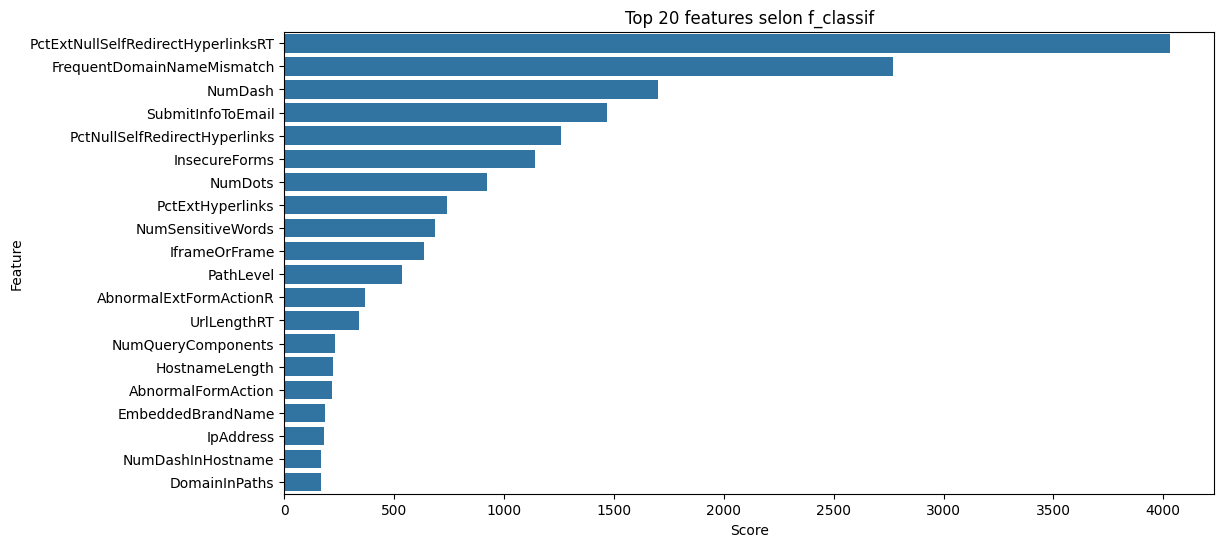

[0]	eval-logloss:0.53630
[1]	eval-logloss:0.43129
[2]	eval-logloss:0.35549
[3]	eval-logloss:0.29880
[4]	eval-logloss:0.25548
[5]	eval-logloss:0.22345
[6]	eval-logloss:0.19843
[7]	eval-logloss:0.17736
[8]	eval-logloss:0.16208
[9]	eval-logloss:0.14882
[10]	eval-logloss:0.13882
[11]	eval-logloss:0.12962
[12]	eval-logloss:0.12248
[13]	eval-logloss:0.11626
[14]	eval-logloss:0.11206
[15]	eval-logloss:0.10695
[16]	eval-logloss:0.10287
[17]	eval-logloss:0.09897
[18]	eval-logloss:0.09690
[19]	eval-logloss:0.09510
[20]	eval-logloss:0.09423
[21]	eval-logloss:0.09193
[22]	eval-logloss:0.09050
[23]	eval-logloss:0.08888
[24]	eval-logloss:0.08776
[25]	eval-logloss:0.08670
[26]	eval-logloss:0.08574
[27]	eval-logloss:0.08532
[28]	eval-logloss:0.08494
[29]	eval-logloss:0.08459
[30]	eval-logloss:0.08494
[31]	eval-logloss:0.08396
[32]	eval-logloss:0.08306
[33]	eval-logloss:0.08278
[34]	eval-logloss:0.08180
[35]	eval-logloss:0.08177
[36]	eval-logloss:0.08145
[37]	eval-logloss:0.08066
[38]	eval-logloss:0.08

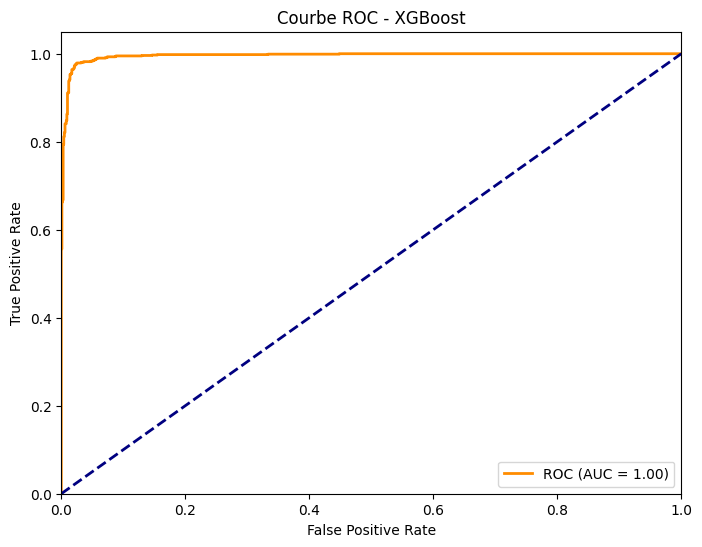


Accuracy sur le jeu de test: 97.60%


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
df = pd.read_csv("Phishing_Legitimate_full.csv")

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
# Retirer les colonnes non pertinentes (exemple : 'id' et 'url')
for col in ['id', 'url']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

# Vérification et affichage de la distribution de la variable cible
print("\nDistribution initiale des classes :", df['CLASS_LABEL'].value_counts())

# Suppression des observations avec une valeur manquante dans la target (si nécessaire)
df.dropna(subset=['CLASS_LABEL'], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=['CLASS_LABEL']).values
y = df['CLASS_LABEL'].values

# ---------------------------
# 2. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X_scaled) - np.sum(mask)
    print(f"Pour une contamination de {contamination}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (ici 0.01)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Sélection des meilleures features avec SelectKBest
# ---------------------------
# Sélectionner les 20 features les plus significatives selon f_classif
selector = SelectKBest(score_func=f_classif, k=20)
selector.fit(X_res, y_res)
X_sel = selector.transform(X_res)
selected_feature_indices = selector.get_support(indices=True)
print("\nIndices des features sélectionnées :", selected_feature_indices)

# (Optionnel) Visualisation des scores des features
feature_scores = selector.scores_
all_features = df.drop(columns=['CLASS_LABEL']).columns
score_df = pd.DataFrame({'Feature': all_features, 'Score': feature_scores})
score_df.sort_values(by='Score', ascending=False, inplace=True)
plt.figure(figsize=(12,6))
sns.barplot(x="Score", y="Feature", data=score_df.head(20))
plt.title("Top 20 features selon f_classif")
plt.show()

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y_res,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_res)

# ---------------------------
# 7. Préparation pour l'entraînement XGBoost (xgb.train)
# ---------------------------
# Conversion des jeux de données en DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest  = xgb.DMatrix(X_test, label=y_test)

# Meilleurs hyperparamètres trouvés :
# learning_rate = 0.2, max_depth = 7, n_estimators (num_boost_round) = 100, subsample = 0.8
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,          # learning_rate
    'subsample': 0.8,
    'seed': 42
}

num_boost_round = 100

# Entraînement avec early stopping (si aucune amélioration pendant 10 itérations, arrêt)
evals = [(dtest, 'eval')]
bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
# Prédictions sur le jeu de test
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred))

# Calcul et affichage de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.show()

print("\nAccuracy sur le jeu de test: {:.2f}%".format(accuracy_score(y_test, y_pred) * 100))


Dimensions du dataset: (10000, 50)
Aperçu des 5 premières lignes:
   id  NumDots  SubdomainLevel  PathLevel  UrlLength  NumDash  \
0   1        3               1          5         72        0   
1   2        3               1          3        144        0   
2   3        3               1          2         58        0   
3   4        3               1          6         79        1   
4   5        3               0          4         46        0   

   NumDashInHostname  AtSymbol  TildeSymbol  NumUnderscore  ...  \
0                  0         0            0              0  ...   
1                  0         0            0              2  ...   
2                  0         0            0              0  ...   
3                  0         0            0              0  ...   
4                  0         0            0              0  ...   

   IframeOrFrame  MissingTitle  ImagesOnlyInForm  SubdomainLevelRT  \
0              0             0                 1                 1   


/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [19] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


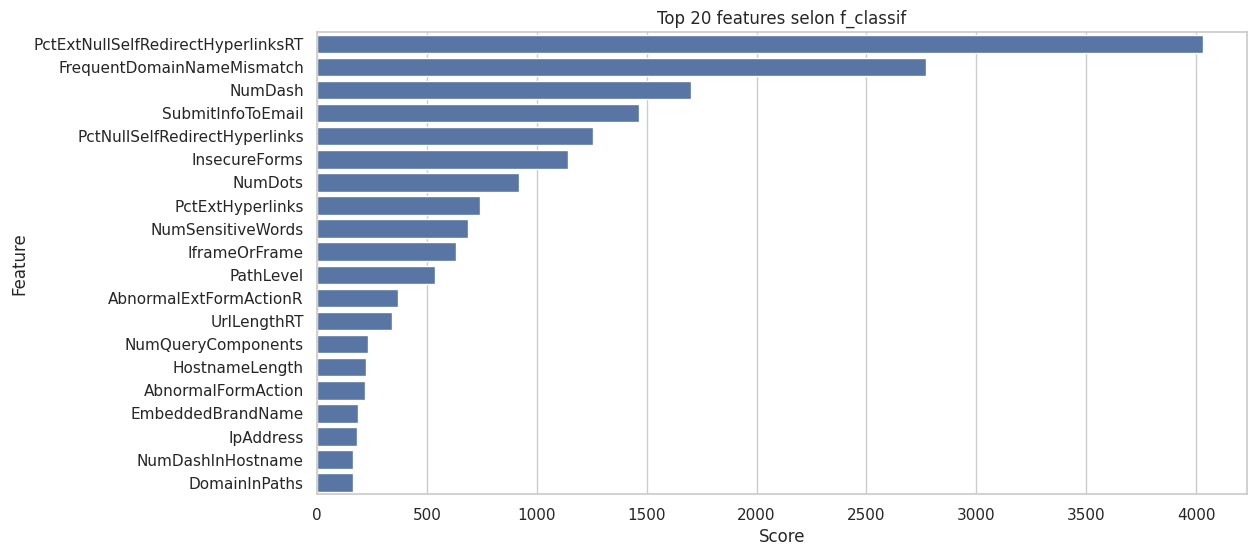

[0]	eval-logloss:0.53630
[1]	eval-logloss:0.43129
[2]	eval-logloss:0.35549
[3]	eval-logloss:0.29880
[4]	eval-logloss:0.25548
[5]	eval-logloss:0.22345
[6]	eval-logloss:0.19843
[7]	eval-logloss:0.17736
[8]	eval-logloss:0.16208
[9]	eval-logloss:0.14882
[10]	eval-logloss:0.13882
[11]	eval-logloss:0.12962
[12]	eval-logloss:0.12248
[13]	eval-logloss:0.11626
[14]	eval-logloss:0.11206
[15]	eval-logloss:0.10695
[16]	eval-logloss:0.10287
[17]	eval-logloss:0.09897
[18]	eval-logloss:0.09690
[19]	eval-logloss:0.09510
[20]	eval-logloss:0.09423
[21]	eval-logloss:0.09193
[22]	eval-logloss:0.09050
[23]	eval-logloss:0.08888
[24]	eval-logloss:0.08776
[25]	eval-logloss:0.08670
[26]	eval-logloss:0.08574
[27]	eval-logloss:0.08532
[28]	eval-logloss:0.08494
[29]	eval-logloss:0.08459
[30]	eval-logloss:0.08494
[31]	eval-logloss:0.08396
[32]	eval-logloss:0.08306
[33]	eval-logloss:0.08278
[34]	eval-logloss:0.08180
[35]	eval-logloss:0.08177
[36]	eval-logloss:0.08145
[37]	eval-logloss:0.08066
[38]	eval-logloss:0.08

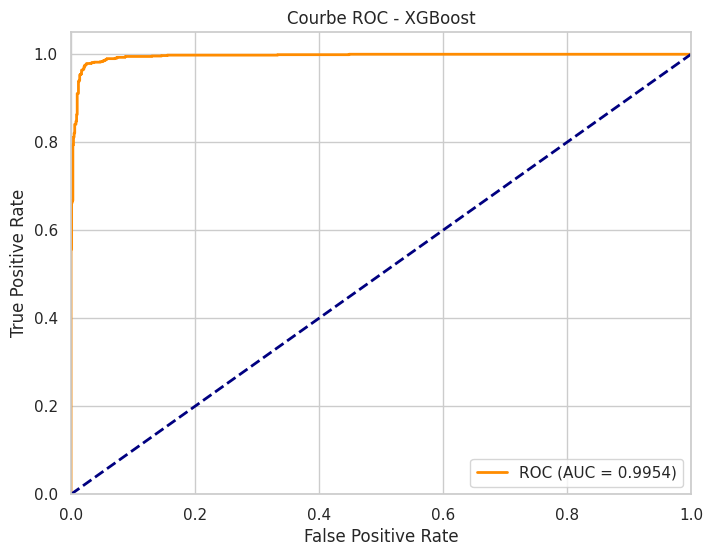


Accuracy sur le jeu de test: 97.5976%


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
df = pd.read_csv("Phishing_Legitimate_full.csv")

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
# Retirer les colonnes non pertinentes (exemple : 'id' et 'url')
for col in ['id', 'url']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

# Vérification et affichage de la distribution de la variable cible
print("\nDistribution initiale des classes :", df['CLASS_LABEL'].value_counts())

# Suppression des observations avec une valeur manquante dans la target (si nécessaire)
df.dropna(subset=['CLASS_LABEL'], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=['CLASS_LABEL']).values
y = df['CLASS_LABEL'].values

# ---------------------------
# 2. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X_scaled) - np.sum(mask)
    print(f"Pour une contamination de {contamination:.4f}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (ici 0.01)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Sélection des meilleures features avec SelectKBest
# ---------------------------
# Sélectionner les 20 features les plus significatives selon f_classif
selector = SelectKBest(score_func=f_classif, k=20)
selector.fit(X_res, y_res)
X_sel = selector.transform(X_res)
selected_feature_indices = selector.get_support(indices=True)
print("\nIndices des features sélectionnées :", selected_feature_indices)

# (Optionnel) Visualisation des scores des features
feature_scores = selector.scores_
all_features = df.drop(columns=['CLASS_LABEL']).columns
score_df = pd.DataFrame({'Feature': all_features, 'Score': feature_scores})
score_df.sort_values(by='Score', ascending=False, inplace=True)
plt.figure(figsize=(12,6))
sns.barplot(x="Score", y="Feature", data=score_df.head(20))
plt.title("Top 20 features selon f_classif")
plt.show()

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y_res,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_res)

# ---------------------------
# 7. Préparation pour l'entraînement XGBoost (xgb.train)
# ---------------------------
# Conversion des jeux de données en DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest  = xgb.DMatrix(X_test, label=y_test)

# Meilleurs hyperparamètres trouvés :
# learning_rate = 0.2, max_depth = 7, n_estimators (num_boost_round) = 100, subsample = 0.8
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,          # learning_rate
    'subsample': 0.8,
    'seed': 42
}

num_boost_round = 100

# Entraînement avec early stopping (si aucune amélioration pendant 10 itérations, arrêt)
evals = [(dtest, 'eval')]
bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

# Enregistrement du modèle au format JSON (par exemple)
bst.save_model("xgb_model.json")
print("\nModèle XGBoost enregistré dans 'xgb_model.json'.")

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
# Prédictions sur le jeu de test
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
print(classification_report(y_test, y_pred, digits=4))

# Calcul et affichage de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC (AUC = {:.4f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - XGBoost')
plt.legend(loc="lower right")
plt.show()

print("\nAccuracy sur le jeu de test: {:.4f}%".format(accuracy_score(y_test, y_pred) * 100))


#xgboost(RFECV)

Dimensions du dataset: (10000, 50)
Aperçu des 5 premières lignes:
   id  NumDots  SubdomainLevel  PathLevel  UrlLength  NumDash  \
0   1        3               1          5         72        0   
1   2        3               1          3        144        0   
2   3        3               1          2         58        0   
3   4        3               1          6         79        1   
4   5        3               0          4         46        0   

   NumDashInHostname  AtSymbol  TildeSymbol  NumUnderscore  ...  \
0                  0         0            0              0  ...   
1                  0         0            0              2  ...   
2                  0         0            0              0  ...   
3                  0         0            0              0  ...   
4                  0         0            0              0  ...   

   IframeOrFrame  MissingTitle  ImagesOnlyInForm  SubdomainLevelRT  \
0              0             0                 1                 1   


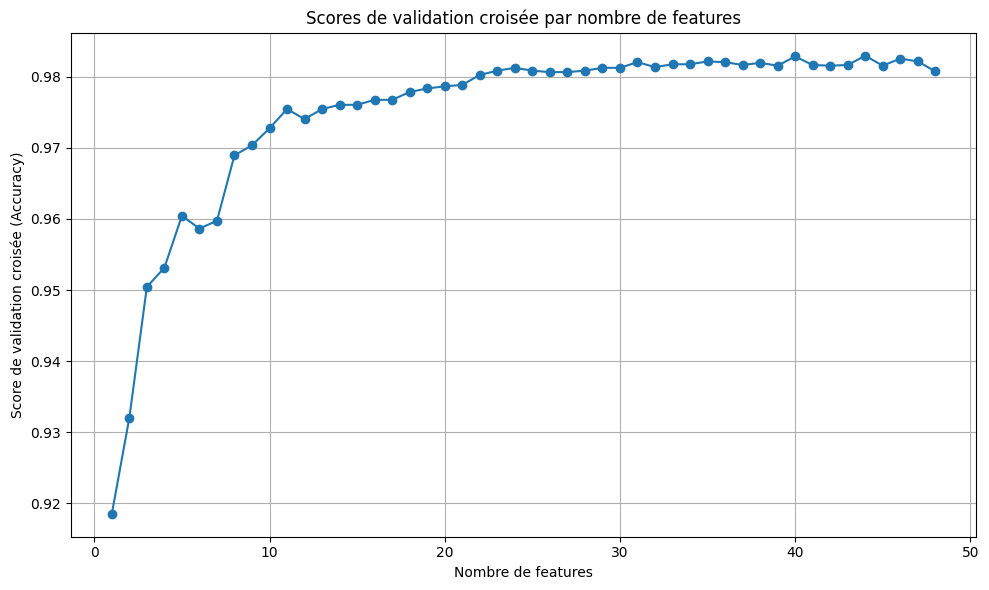


Entraînement du modèle XGBoost...
[0]	eval-logloss:0.53397
[1]	eval-logloss:0.42760
[2]	eval-logloss:0.35108
[3]	eval-logloss:0.29407
[4]	eval-logloss:0.25015
[5]	eval-logloss:0.21593
[6]	eval-logloss:0.18820
[7]	eval-logloss:0.16578
[8]	eval-logloss:0.14916
[9]	eval-logloss:0.13484
[10]	eval-logloss:0.12376
[11]	eval-logloss:0.11507
[12]	eval-logloss:0.10707
[13]	eval-logloss:0.09903
[14]	eval-logloss:0.09459
[15]	eval-logloss:0.08866
[16]	eval-logloss:0.08381
[17]	eval-logloss:0.08015
[18]	eval-logloss:0.07679
[19]	eval-logloss:0.07312
[20]	eval-logloss:0.07133
[21]	eval-logloss:0.06918
[22]	eval-logloss:0.06794
[23]	eval-logloss:0.06615
[24]	eval-logloss:0.06478
[25]	eval-logloss:0.06208
[26]	eval-logloss:0.06059
[27]	eval-logloss:0.05906
[28]	eval-logloss:0.05756
[29]	eval-logloss:0.05595
[30]	eval-logloss:0.05422
[31]	eval-logloss:0.05346
[32]	eval-logloss:0.05297
[33]	eval-logloss:0.05216
[34]	eval-logloss:0.05161
[35]	eval-logloss:0.05120
[36]	eval-logloss:0.05094
[37]	eval-log

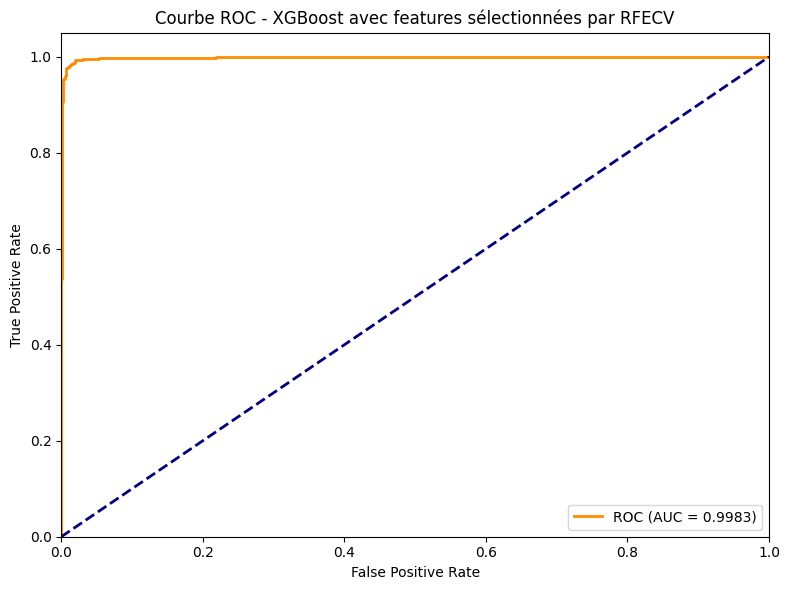


Accuracy sur le jeu de test: 98.4985%


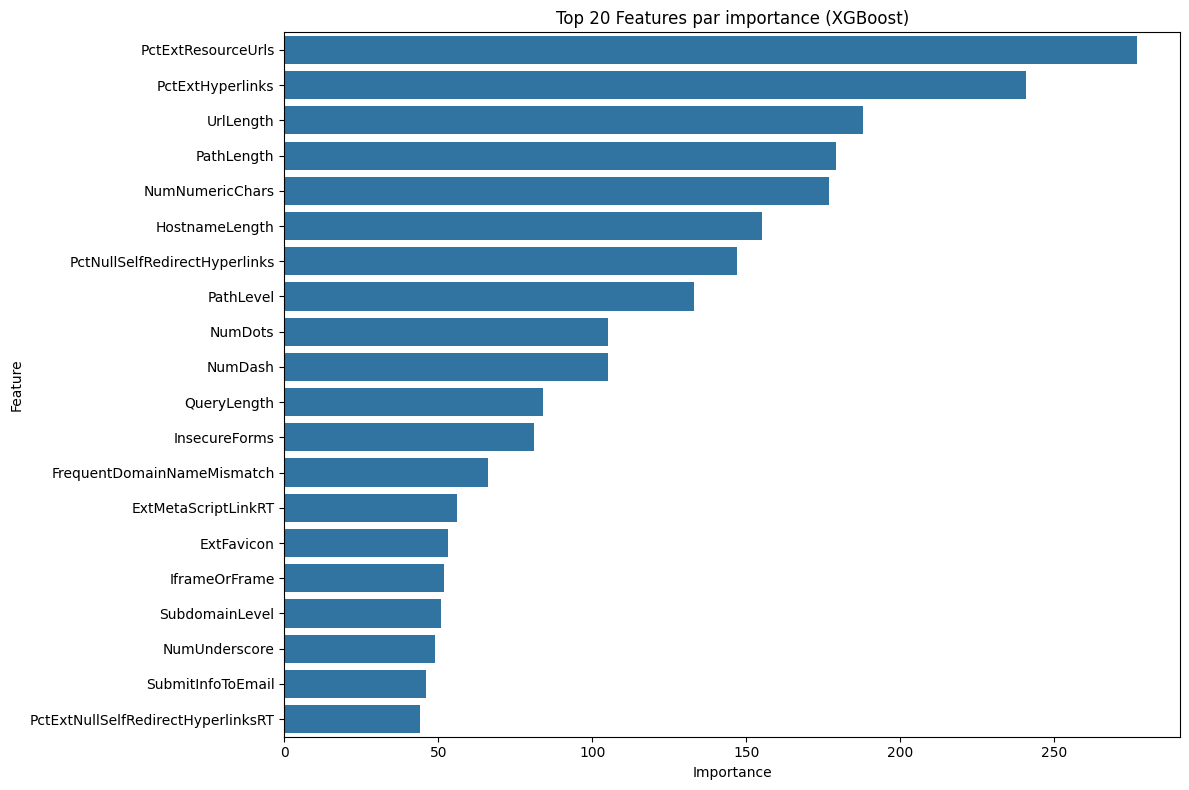


Réalisation de la validation croisée sur le modèle final...
Scores de validation croisée: [0.984  0.987  0.982  0.989  0.9865]
Score moyen de validation croisée: 0.9857
Écart type des scores: 0.0024

Modèle sauvegardé : xgboost_phishing_model_rfecv.model


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [14:36:20] WARNING: /workspace/src/c_api/c_api.cc:1374: Saving model in the UBJSON format as default.  You can use file extension: `json`, `ubj` or `deprecated` to choose between formats.
  warnings.warn(smsg, UserWarning)


In [ ]:
# Importation des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc, accuracy_score
from sklearn.feature_selection import RFECV

from sklearn.ensemble import IsolationForest, RandomForestClassifier
from imblearn.over_sampling import SMOTE

import xgboost as xgb

# Set display precision
np.set_printoptions(precision=4)
pd.set_option('display.precision', 4)

# ---------------------------
# 0. Chargement et exploration du dataset
# ---------------------------
df = pd.read_csv("Phishing_Legitimate_full.csv")

print("Dimensions du dataset:", df.shape)
print("Aperçu des 5 premières lignes:")
print(df.head())

print("\nInformations sur le dataset:")
df.info()

print("\nStatistiques descriptives:")
print(df.describe())

# ---------------------------
# 1. Préparation des données
# ---------------------------
# Retirer les colonnes non pertinentes (exemple : 'id' et 'url')
for col in ['id', 'url']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

# Vérification et affichage de la distribution de la variable cible
print("\nDistribution initiale des classes :", df['CLASS_LABEL'].value_counts())

# Suppression des observations avec une valeur manquante dans la target (si nécessaire)
df.dropna(subset=['CLASS_LABEL'], inplace=True)

# Séparation des features et de la cible
X = df.drop(columns=['CLASS_LABEL']).values
y = df['CLASS_LABEL'].values
feature_names = df.drop(columns=['CLASS_LABEL']).columns

# ---------------------------
# 2. Normalisation des features
# ---------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------
# 3. Détection et suppression des anomalies avec IsolationForest
# ---------------------------
print("\nDétection d'anomalies avec IsolationForest:")
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X_scaled)
    mask = pred_anomalies != -1
    nombre_supprimes = len(X_scaled) - np.sum(mask)
    print(f"Pour une contamination de {contamination:.4f}, points supprimés : {nombre_supprimes}")

# Choix du taux de contamination (ici 0.01)
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X_scaled)
mask = pred_anomalies != -1
X_scaled = X_scaled[mask]
y = y[mask]

# ---------------------------
# 4. Équilibrage de la dataset avec SMOTE
# ---------------------------
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)
print("\nDistribution des classes après SMOTE:", np.bincount(y_res))

# ---------------------------
# 5. Utilisation de RFECV pour la sélection des features
# ---------------------------
# Instancier un estimateur pour la sélection (RandomForest est un bon choix ici)
base_estimator = RandomForestClassifier(n_estimators=100, random_state=42)

# Configuration du RFECV
rfecv = RFECV(
    estimator=base_estimator,
    step=1,  # Éliminer 1 feature à chaque itération
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1,  # Utiliser tous les processeurs disponibles
    verbose=1
)

# Ajustement du RFECV sur les données
print("\nExécution de la sélection de features avec RFECV...")
rfecv.fit(X_res, y_res)

# Affichage des résultats
print(f"\nNombre optimal de features: {rfecv.n_features_:.4f}")
print(f"Score CV avec {rfecv.n_features_} features: {rfecv.cv_results_['mean_test_score'][rfecv.n_features_ - 1]:.4f}")

# Récupérer les features sélectionnées
selected_features_mask = rfecv.support_
selected_features_indices = np.where(selected_features_mask)[0]
selected_feature_names = feature_names[selected_features_mask]

print("\nFeatures sélectionnées:")
for i, feature in enumerate(selected_feature_names):
    print(f"{i+1}. {feature}")

# Visualisation des scores par nombre de features
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'], marker='o')
plt.title("Scores de validation croisée par nombre de features")
plt.xlabel("Nombre de features")
plt.ylabel("Score de validation croisée (Accuracy)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Application de la transformation pour garder uniquement les features sélectionnées
X_sel = rfecv.transform(X_res)

# ---------------------------
# 6. Split train/test
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X_sel, y_res,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y_res)

# ---------------------------
# 7. Préparation pour l'entraînement XGBoost (xgb.train)
# ---------------------------
# Conversion des jeux de données en DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

# Meilleurs hyperparamètres trouvés :
# learning_rate = 0.2, max_depth = 7, n_estimators (num_boost_round) = 100, subsample = 0.8
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'max_depth': 7,
    'eta': 0.2,          # learning_rate
    'subsample': 0.8,
    'seed': 42
}

num_boost_round = 100

# Entraînement avec early stopping (si aucune amélioration pendant 10 itérations, arrêt)
evals = [(dtest, 'eval')]
print("\nEntraînement du modèle XGBoost...")
bst = xgb.train(params,
                dtrain,
                num_boost_round=num_boost_round,
                evals=evals,
                early_stopping_rounds=10,
                verbose_eval=True)

print(f"\nMeilleure itération: {bst.best_iteration}")
print(f"Meilleur score: {bst.best_score:.4f}")

# ---------------------------
# 8. Évaluation du modèle
# ---------------------------
# Prédictions sur le jeu de test
y_proba = bst.predict(dtest)
y_pred = (y_proba >= 0.5).astype(int)

print("\n--- Rapport de classification ---")
report = classification_report(y_test, y_pred, digits=4)
print(report)

# Calcul et affichage de la courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC - XGBoost avec features sélectionnées par RFECV')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"\nAccuracy sur le jeu de test: {accuracy_score(y_test, y_pred) * 100:.4f}%")

# ---------------------------
# 9. Visualisation de l'importance des features
# ---------------------------
# Récupérer l'importance des features depuis XGBoost
if hasattr(bst, 'get_score'):
    # Pour xgb.train
    importance_dict = bst.get_score(importance_type='weight')
    # Convertir en format plus facile à visualiser
    importance_list = []
    for i in range(X_sel.shape[1]):
        f_name = f'f{i}'  # xgboost utilise f0, f1, etc.
        if f_name in importance_dict:
            importance_list.append((selected_feature_names[i], importance_dict[f_name]))
        else:
            importance_list.append((selected_feature_names[i], 0))

    # Trier par importance
    importance_list.sort(key=lambda x: x[1], reverse=True)

    # Créer un DataFrame pour la visualisation
    importance_df = pd.DataFrame(importance_list, columns=['Feature', 'Importance'])

    # Afficher l'importance des features
    plt.figure(figsize=(12, 8))
    ax = sns.barplot(x='Importance', y='Feature', data=importance_df.head(20))
    plt.title('Top 20 Features par importance (XGBoost)')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

# ---------------------------
# 10. Validation croisée sur le modèle final
# ---------------------------
print("\nRéalisation de la validation croisée sur le modèle final...")

# Convertir les paramètres pour sklearn
xgb_clf = xgb.XGBClassifier(
    max_depth=7,
    learning_rate=0.2,
    n_estimators=bst.best_iteration if hasattr(bst, 'best_iteration') else num_boost_round,
    subsample=0.8,
    random_state=42
)

# CV stratifiée avec 5 splits
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_clf, X_sel, y_res, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"Scores de validation croisée: {cv_scores}")
print(f"Score moyen de validation croisée: {cv_scores.mean():.4f}")
print(f"Écart type des scores: {cv_scores.std():.4f}")

# Sauvegarder le modèle
bst.save_model('xgboost_phishing_model_rfecv.model')
print("\nModèle sauvegardé : xgboost_phishing_model_rfecv.model")